In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

In [2]:
df = pd.read_csv("../data/raw/creditcard.csv")
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
X = df.drop("Class", axis=1)
y = df["Class"]

In [4]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (284807, 30)
y shape: (284807,)


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (227845, 30)
Testing data: (56962, 30)


In [6]:
X_train = X_train.copy()
X_test = X_test.copy()

X_train["TransactionHour"] = (
    (X_train["Time"] // 3600) % 24
)

X_test["TransactionHour"] = (
    (X_test["Time"] // 3600) % 24
)

In [7]:
X_train[["Time", "TransactionHour"]].head()

,Time,TransactionHour
265518,161919.0,20.0
180305,124477.0,10.0
42664,41191.0,11.0
198723,132624.0,12.0
82325,59359.0,16.0


In [8]:
X_train["HourSin"] = np.sin(
    2 * np.pi * X_train["TransactionHour"] / 24
)

X_train["HourCos"] = np.cos(
    2 * np.pi * X_train["TransactionHour"] / 24
)

X_test["HourSin"] = np.sin(
    2 * np.pi * X_test["TransactionHour"] / 24
)

X_test["HourCos"] = np.cos(
    2 * np.pi * X_test["TransactionHour"] / 24
)

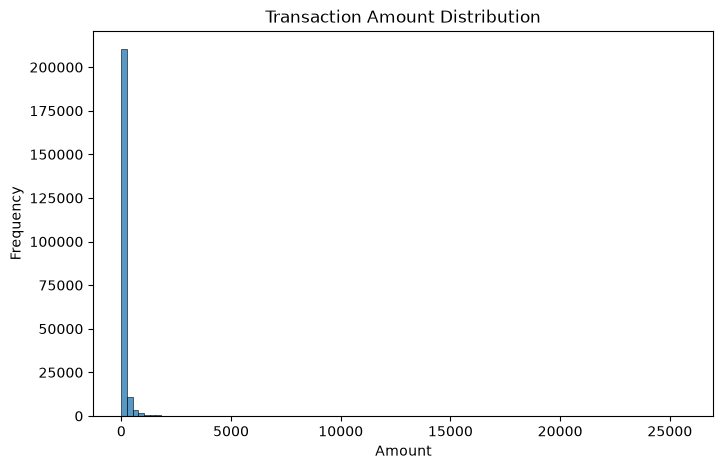

In [9]:
plt.figure(figsize=(8, 5))

sns.histplot(
    X_train["Amount"],
    bins=100
)

plt.title("Transaction Amount Distribution")
plt.xlabel("Amount")
plt.ylabel("Frequency")

plt.show()

In [10]:
X_train["AmountLog"] = np.log1p(X_train["Amount"])
X_test["AmountLog"] = np.log1p(X_test["Amount"])

In [11]:
X_train["AmountBucket"] = pd.cut(
    X_train["Amount"],
    bins=[-1, 10, 50, 100, 500, 1000, np.inf],
    labels=False
)

X_test["AmountBucket"] = pd.cut(
    X_test["Amount"],
    bins=[-1, 10, 50, 100, 500, 1000, np.inf],
    labels=False
)

In [12]:
print("Original features:", X.shape[1])
print("New training features:", X_train.shape[1])
print("New testing features:", X_test.shape[1])

Original features: 30
New training features: 35
New testing features: 35


In [13]:
X_train.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V25,V26,V27,V28,Amount,TransactionHour,HourSin,HourCos,AmountLog,AmountBucket
265518,161919.0,1.946747,-0.752526,-1.355130,-0.661630,1.502822,4.024933,-1.479661,1.139880,1.406819,...,-0.350316,-0.388907,0.077641,-0.032248,7.32,20.0,-8.660254e-01,0.500000,2.118662,0
180305,124477.0,2.035149,-0.048880,-3.058693,0.247945,2.943487,3.298697,-0.002192,0.674782,0.045826,...,0.512885,-0.471198,0.002520,-0.069002,2.99,10.0,5.000000e-01,-0.866025,1.383791,0
42664,41191.0,-0.991920,0.603193,0.711976,-0.992425,-0.825838,1.956261,-2.212603,-5.037523,0.000772,...,0.826684,0.913773,0.038049,0.185340,175.10,11.0,2.588190e-01,-0.965926,5.171052,3
198723,132624.0,2.285718,-1.500239,-0.747565,-1.668119,-1.394143,-0.350339,-1.427984,0.010010,-1.118447,...,-0.278032,-0.162068,0.018045,-0.063005,6.10,12.0,1.224647e-16,-1.000000,1.960095,0
82325,59359.0,-0.448747,-1.011440,0.115903,-3.454854,0.715771,-0.147490,0.504347,-0.113817,-0.044782,...,-0.292234,-0.144622,-0.032580,-0.064194,86.10,16.0,-8.660254e-01,-0.500000,4.467057,2


In [14]:
train_analysis = X_train.copy()
train_analysis["Class"] = y_train.values

In [15]:
train_analysis.groupby("Class")[
    ["Amount", "AmountLog", "TransactionHour"]
].mean()

,Amount,AmountLog,TransactionHour
Class,,,
0,88.111486,3.153620,14.054139
1,125.591472,2.829126,11.675127


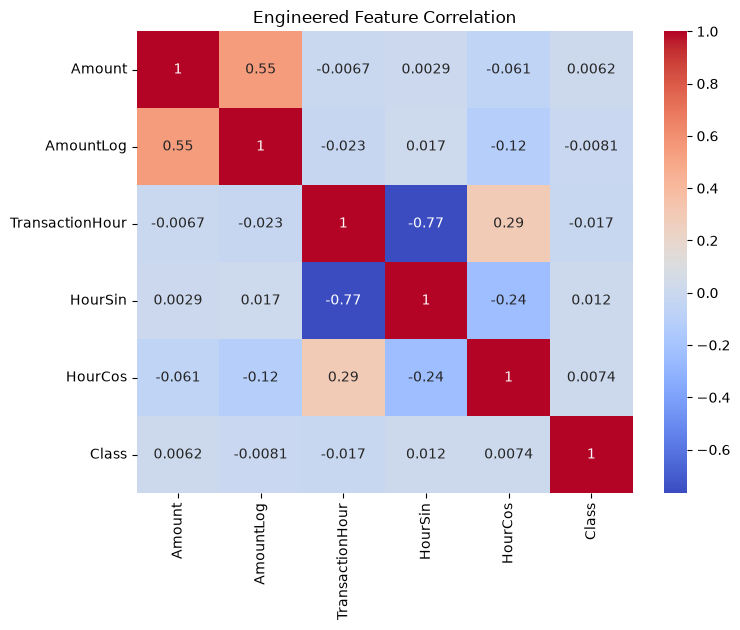

In [16]:
correlation = train_analysis[
    ["Amount", "AmountLog", "TransactionHour", "HourSin", "HourCos", "Class"]
].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm"
)

plt.title("Engineered Feature Correlation")

plt.show()